> 📖 Book: [ch02 – Eigen, SVD](../../.claude/skills/ml-knowledge/chapters/ch02-linear-algebra-eigen-svd.md) · Prev: [03](03_linear_inversion_problem.ipynb) · Next: [05 SVD, low rank and dynamical systems](05_svd_low_rank_and_dynamical_systems.ipynb)

# Orthogonal and Unitary Matrices

The singular value decomposition of [05](05_svd_low_rank_and_dynamical_systems.ipynb) writes every matrix as $A = U\Sigma V^H$ with $U$ and $V$ **unitary**, and the discrete Fourier transform is a multiplication by a unitary matrix too. [03](03_linear_inversion_problem.ipynb) left one question open: why are some systems $A\mathbf{x} = \mathbf{b}$ stable and others not? Stability depends on how unevenly a matrix stretches the space, so we start with the matrices that do not stretch it at all, and §6 shows they are perfectly stable, $\kappa = 1$. This notebook explains what "unitary" means and why it keeps showing up:

| Idea | Section |
|---|---|
| Transformations that move the space without deforming it | §1 |
| Definition: $U^HU = I$ | §2 |
| What is preserved: lengths, angles, energy | §3 |
| Why complex numbers appear | §4 |
| Changing coordinates does **not** require a unitary matrix | §5 |
| Why unitary bases are still the preferred ones: $\kappa(U) = 1$ | §6 |
| The DFT as a unitary change of basis (Parseval) | §7 |
| The SVD: all the deformation lives in $\Sigma$ | §8 |

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from ml.linalg import condition_number, dft_matrix, low_rank_approx
from ml.visualization.plots import plot_linear_map

plt.style.use("seaborn-v0_8-whitegrid")
rng = np.random.default_rng(0)

## 1. Transformations that do not deform

A matrix $A$ acts on a vector $\mathbf{x}$ by $\mathbf{y} = A\mathbf{x}$. A general matrix can rotate, reflect, stretch, compress and shear the space. A **unitary** matrix (in the real case, an **orthogonal** matrix) can only rotate, reflect or change phase: it never alters lengths or the angles between vectors.

> Picture a figure drawn on a rigid sheet. You may turn the sheet or flip it over, but you cannot stretch it.

The figure applies four $2\times 2$ matrices to a square grid, the unit circle and the standard basis $\mathbf{e}_1$, $\mathbf{e}_2$. The first two keep the circle a circle and the grid square: they are orthogonal. The last two do not.

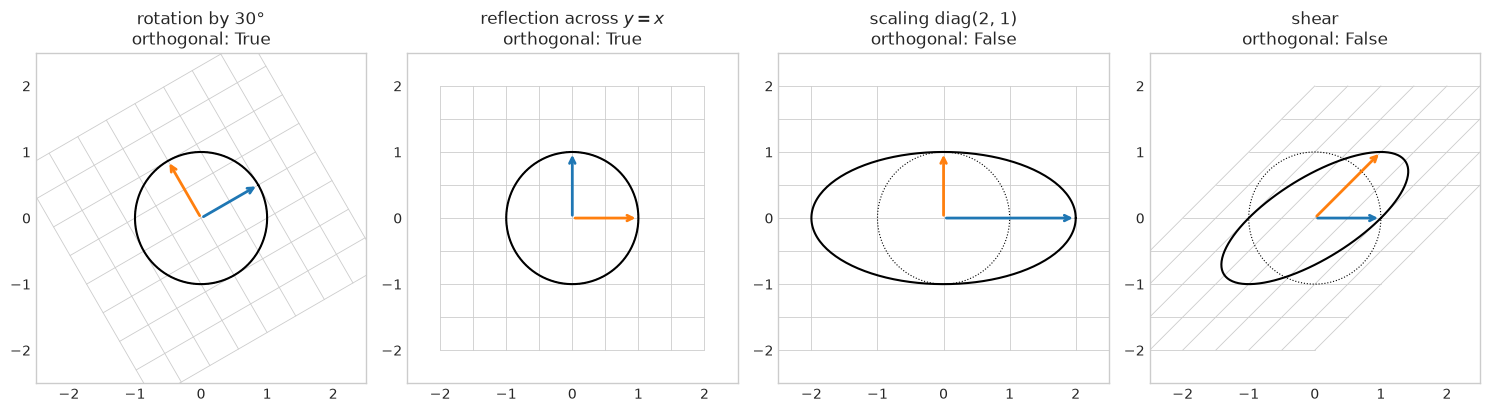

In [2]:
theta = np.pi / 6
maps = {
    "rotation by 30°": np.array([[np.cos(theta), -np.sin(theta)], [np.sin(theta), np.cos(theta)]]),
    "reflection across $y = x$": np.array([[0.0, 1.0], [1.0, 0.0]]),
    "scaling diag(2, 1)": np.array([[2.0, 0.0], [0.0, 1.0]]),
    "shear": np.array([[1.0, 1.0], [0.0, 1.0]]),
}
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, (name, M) in zip(ax, maps.items(), strict=True):
    is_orthogonal = np.allclose(M.T @ M, np.eye(2))
    plot_linear_map(a, M, f"{name}\northogonal: {is_orthogonal}")
fig.tight_layout()
plt.show()

## 2. Definition

For complex matrices the right notion of transpose is the **conjugate transpose** (adjoint), $A^H = \overline{A}^T$. A square matrix $U$ is **unitary** if

$$
\boxed{U^H U = U U^H = I},
$$

which is the same as saying that its inverse is its conjugate transpose:

$$
\boxed{U^{-1} = U^H}.
$$

Inverting a unitary matrix costs nothing: transpose and conjugate.

**The real case.** If every entry is real, conjugation does nothing and $U^H = U^T$. The condition becomes $Q^TQ = I$, the definition of an **orthogonal** matrix:

> An orthogonal matrix is the real version of a unitary matrix.

Equivalently, the columns $\mathbf{u}_1, \dots, \mathbf{u}_n$ of a unitary matrix form an **orthonormal basis**: entry $(i, j)$ of $U^HU$ is $\mathbf{u}_i^H\mathbf{u}_j$, so $U^HU = I$ says

$$
\mathbf{u}_i^H \mathbf{u}_j =
\begin{cases}
1 & i = j\\
0 & i \neq j.
\end{cases}
$$

**Example.** The $90^\circ$ rotation

$$
Q = \begin{bmatrix} 0 & -1 \\ 1 & 0 \end{bmatrix},
\qquad
Q^T = \begin{bmatrix} 0 & 1 \\ -1 & 0 \end{bmatrix},
\qquad
Q^TQ = I.
$$

It sends $\mathbf{x} = [1, 0]^T$ to $Q\mathbf{x} = [0, 1]^T$: the direction changes, the length stays $\|\mathbf{x}\| = \|Q\mathbf{x}\| = 1$.

In [3]:
Q = np.array([[0.0, -1.0], [1.0, 0.0]])
x = np.array([1.0, 0.0])
print("Q^T Q == I:", np.allclose(Q.T @ Q, np.eye(2)), "| Q^-1 == Q^T:", np.allclose(np.linalg.inv(Q), Q.T))
print("Qx =", Q @ x, "| ||x|| =", np.linalg.norm(x), "| ||Qx|| =", np.linalg.norm(Q @ x))

Q^T Q == I: True | Q^-1 == Q^T: True
Qx = [0. 1.] | ||x|| = 1.0 | ||Qx|| = 1.0


## 3. What a unitary matrix preserves

**Length.** Let $\mathbf{x} \in \mathbb{C}^n$ and $\mathbf{y} = U\mathbf{x}$. Then

$$
\|U\mathbf{x}\|^2 = (U\mathbf{x})^H(U\mathbf{x}) = \mathbf{x}^H U^H U \mathbf{x} = \mathbf{x}^H\mathbf{x} = \|\mathbf{x}\|^2,
\qquad\text{so}\qquad
\boxed{\|U\mathbf{x}\| = \|\mathbf{x}\|}.
$$

**Inner products.** The same computation for two vectors gives

$$
\langle U\mathbf{x}, U\mathbf{y}\rangle = (U\mathbf{x})^H(U\mathbf{y}) = \mathbf{x}^HU^HU\mathbf{y} = \mathbf{x}^H\mathbf{y},
\qquad\text{so}\qquad
\boxed{\langle U\mathbf{x}, U\mathbf{y}\rangle = \langle \mathbf{x}, \mathbf{y}\rangle}.
$$

Lengths and inner products determine angles, so a unitary matrix preserves

- lengths,
- angles,
- orthogonality: if $\mathbf{x}^H\mathbf{y} = 0$ then $(U\mathbf{x})^H(U\mathbf{y}) = 0$.

In signal-processing language, $\|\mathbf{x}\|^2 = \sum_n |x_n|^2$ is the **energy** of a discrete signal, and a unitary matrix does not change it. §7 returns to this as Parseval's theorem.

The QR decomposition of a random complex matrix gives a random unitary $Q$; the cell checks the three properties on random vectors.

In [4]:
n = 6
U, _ = np.linalg.qr(rng.normal(size=(n, n)) + 1j * rng.normal(size=(n, n)))
x, y = rng.normal(size=n) + 1j * rng.normal(size=n), rng.normal(size=n) + 1j * rng.normal(size=n)
y_perp = y - (x.conj() @ y) / (x.conj() @ x) * x  # orthogonal to x


def angle(a, b):
    return np.degrees(np.arccos(abs(a.conj() @ b) / (np.linalg.norm(a) * np.linalg.norm(b))))


print("U^H U == I:", np.allclose(U.conj().T @ U, np.eye(n)))
print(f"||x|| = {np.linalg.norm(x):.6f}, ||Ux|| = {np.linalg.norm(U @ x):.6f}")
print(f"angle(x, y) = {angle(x, y):.4f}°, angle(Ux, Uy) = {angle(U @ x, U @ y):.4f}°")
print(f"x^H y_perp = {abs(x.conj() @ y_perp):.1e}, (Ux)^H (U y_perp) = {abs((U @ x).conj() @ (U @ y_perp)):.1e}")

U^H U == I: True
||x|| = 3.680565, ||Ux|| = 3.680565
angle(x, y) = 79.9925°, angle(Ux, Uy) = 79.9925°
x^H y_perp = 7.0e-16, (Ux)^H (U y_perp) = 5.3e-15


## 4. Why complex numbers appear

Unitary matrices generalize rotations, and in the complex plane a rotation is a multiplication. By Euler's formula

$$
e^{j\theta} = \cos\theta + j\sin\theta, \qquad |e^{j\theta}| = 1,
$$

so $z' = e^{j\theta}z$ turns $z$ by the angle $\theta$ without changing its magnitude: $|z'| = |z|$. A $1\times1$ unitary matrix is exactly such a phase factor, and an $n\times n$ unitary matrix is the multidimensional version of the idea. One consequence: if $U\mathbf{v} = \lambda\mathbf{v}$, then $\|\mathbf{v}\| = \|U\mathbf{v}\| = |\lambda|\,\|\mathbf{v}\|$, so **every eigenvalue of a unitary matrix lies on the unit circle**. Each one is a pure phase rotation along its eigenvector.

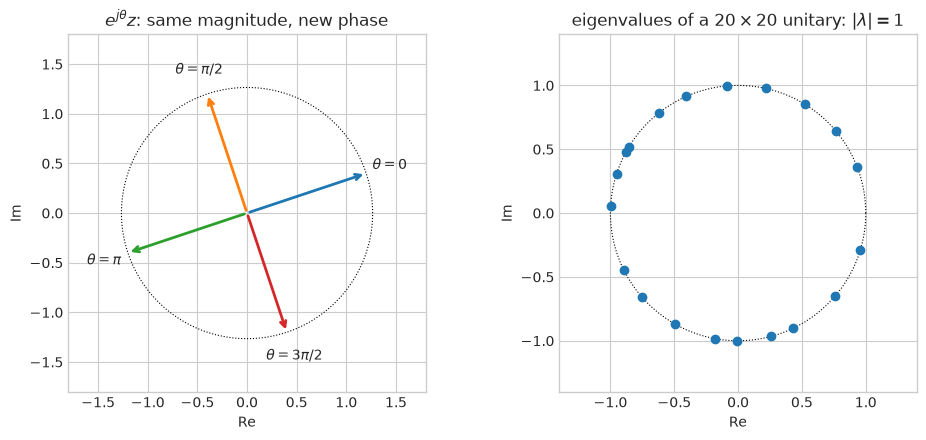

In [5]:
z = 1.2 + 0.4j
angle_grid = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
ax[0].plot(np.cos(angle_grid) * abs(z), np.sin(angle_grid) * abs(z), "k:", lw=0.8)
for k, label in enumerate(("0", r"\pi/2", r"\pi", r"3\pi/2")):
    w = np.exp(1j * k * np.pi / 2) * z
    ax[0].annotate("", (w.real, w.imag), (0, 0), arrowprops={"arrowstyle": "->", "color": f"C{k}", "lw": 2})
    ax[0].text(1.2 * w.real, 1.2 * w.imag, rf"$\theta = {label}$", ha="center", va="center")
ax[0].set(xlim=(-1.8, 1.8), ylim=(-1.8, 1.8), aspect="equal", xlabel="Re", ylabel="Im", title=r"$e^{j\theta}z$: same magnitude, new phase")

U20, _ = np.linalg.qr(rng.normal(size=(20, 20)) + 1j * rng.normal(size=(20, 20)))
eig = np.linalg.eigvals(U20)
ax[1].plot(np.cos(angle_grid), np.sin(angle_grid), "k:", lw=0.8)
ax[1].plot(eig.real, eig.imag, "o")
ax[1].set(xlim=(-1.4, 1.4), ylim=(-1.4, 1.4), aspect="equal", xlabel="Re", ylabel="Im", title=r"eigenvalues of a $20\times20$ unitary: $|\lambda| = 1$")
fig.tight_layout()
plt.show()

## 5. Changing coordinates does not require a unitary matrix

If unitary matrices are the ones that do not deform, is a non-unitary matrix useless for changing coordinates? No. The key is to separate two readings of the same product $\mathbf{y} = A\mathbf{x}$:

- **Active transformation:** $A$ moves the vector. It can rotate, stretch, compress or shear it, and the geometric object changes (§1).
- **Passive transformation:** the vector stays where it is and only its **description** changes, because we measure it against another basis.

The same matrix algebra serves both, and only the first one "deforms" anything.

### 5.1 An oblique basis

Take the basis $\mathbf{b}_1 = [1, 0]^T$, $\mathbf{b}_2 = [1, 1]^T$. It is a valid basis (the vectors are linearly independent) but not orthogonal, since $\mathbf{b}_1^T\mathbf{b}_2 = 1$. Stack it as the columns of

$$
B = \begin{bmatrix} 1 & 1 \\ 0 & 1 \end{bmatrix}.
$$

If $[\mathbf{v}]_\mathcal{E}$ are the coordinates of $\mathbf{v}$ in the standard basis and $[\mathbf{v}]_\mathcal{B}$ those in the new one, then

$$
[\mathbf{v}]_\mathcal{E} = B[\mathbf{v}]_\mathcal{B},
\qquad
[\mathbf{v}]_\mathcal{B} = B^{-1}[\mathbf{v}]_\mathcal{E}.
$$

$B$ is not unitary (it is the shear of §1), but it relates the two coordinate systems perfectly. The only requirement for a change of basis is that it can be undone:

$$
\boxed{\det B \neq 0} \quad\Longleftrightarrow\quad \boxed{\operatorname{rank} B = n}.
$$

| Matrix | Invertible? | Preserves lengths? | Valid change of basis? |
|---|---|---|---|
| Unitary | yes | yes | yes |
| Invertible, not unitary | yes | not in general | yes |
| Singular | no | no | no |

### 5.2 Why the orthonormal case is easier

With an orthonormal basis, $\mathbf{v} = \sum_i c_i\mathbf{u}_i$ and a single inner product extracts each coordinate,

$$
\boxed{c_i = \mathbf{u}_i^H\mathbf{v}},
$$

because every other term is killed by $\mathbf{u}_i^H\mathbf{u}_j = 0$. With an oblique basis, $\mathbf{v} = c_1\mathbf{b}_1 + c_2\mathbf{b}_2$ and the same trick fails:

$$
\mathbf{b}_1^T\mathbf{v} = c_1\,\mathbf{b}_1^T\mathbf{b}_1 + c_2\,\mathbf{b}_1^T\mathbf{b}_2,
$$

the basis vectors "mix". Collecting all the inner products gives a linear system with the **Gram matrix** $G = B^TB$ (entries $\mathbf{b}_i^T\mathbf{b}_j$):

$$
B^T\mathbf{v} = G\,\mathbf{c} \quad\Longrightarrow\quad \mathbf{c} = G^{-1}B^T\mathbf{v}.
$$

The rows of $G^{-1}B^T = B^{-1}$ are the **dual basis**: the vectors whose inner products with $\mathbf{v}$ do give the coordinates. For an orthonormal basis $G = I$, the dual basis is the basis itself, and the system disappears.

The figure shows the same vector $\mathbf{v}$ in both bases. On the left, coordinates come from orthogonal projections. On the right, they come from the parallelogram rule, and the orthogonal projection onto $\mathbf{b}_1$ (dotted) is **not** $c_1\mathbf{b}_1$.

Gram matrix G =
 [[1. 1.]
 [1. 2.]]
coordinates in B: c = [1. 1.] | B^-1 v = [1. 1.]
naive b_1^T v = 2.0 != c_1 = 1.0


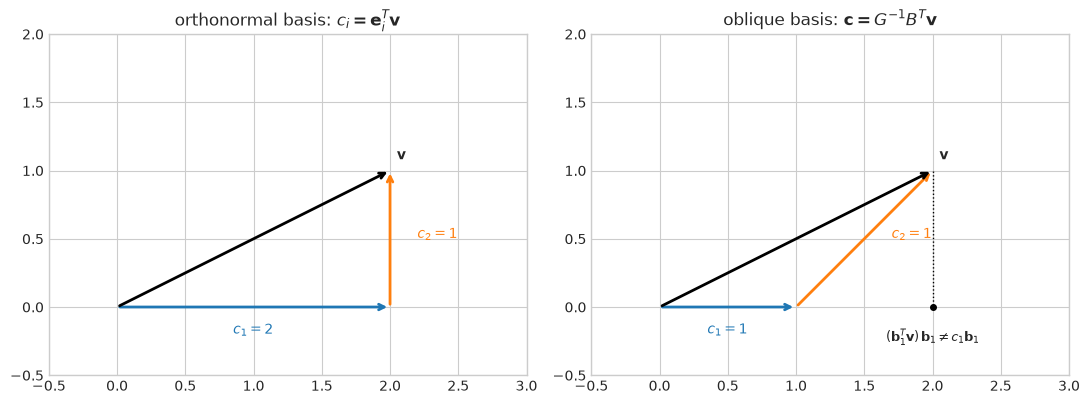

In [6]:
v = np.array([2.0, 1.0])
B = np.array([[1.0, 1.0], [0.0, 1.0]])
G = B.T @ B
c = np.linalg.solve(G, B.T @ v)
print("Gram matrix G =\n", G)
print("coordinates in B: c =", c, "| B^-1 v =", np.linalg.solve(B, v))
print("naive b_1^T v =", B[:, 0] @ v, "!= c_1 =", c[0])


def arrow(a, start, end, color, **kw):
    a.annotate("", end, start, arrowprops={"arrowstyle": "->", "color": color, "lw": 2, **kw})


fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
E = np.eye(2)
for a, basis, coords, title in (
    (ax[0], E, v, r"orthonormal basis: $c_i = \mathbf{e}_i^T\mathbf{v}$"),
    (ax[1], B, c, r"oblique basis: $\mathbf{c} = G^{-1}B^T\mathbf{v}$"),
):
    first = coords[0] * basis[:, 0]
    arrow(a, (0, 0), first, "C0")
    arrow(a, first, v, "C1")
    arrow(a, (0, 0), v, "k")
    a.text(*(first / 2 + [0, -0.2]), f"$c_1 = {coords[0]:g}$", color="C0", ha="center")
    a.text(*((first + v) / 2 + [0.2, 0]), f"$c_2 = {coords[1]:g}$", color="C1")
    a.text(*(v + [0.05, 0.08]), r"$\mathbf{v}$")
    a.set(xlim=(-0.5, 3), ylim=(-0.5, 2), aspect="equal", title=title)
proj = (B[:, 0] @ v) / (B[:, 0] @ B[:, 0]) * B[:, 0]
ax[1].plot(*np.vstack([v, proj]).T, "k:", lw=1)
ax[1].plot(*proj, "ko", ms=4)
ax[1].text(proj[0], proj[1] - 0.25, r"$(\mathbf{b}_1^T\mathbf{v})\,\mathbf{b}_1 \neq c_1\mathbf{b}_1$", ha="center", fontsize=9)
fig.tight_layout()
plt.show()

## 6. Why unitary bases are still preferred: $\kappa(U) = 1$

All singular values of a unitary matrix equal 1 (it maps the unit sphere onto itself), so its condition number is

$$
\boxed{\kappa(U) = \frac{\sigma_{\max}}{\sigma_{\min}} = 1}.
$$

A change of coordinates through $U$ cannot amplify relative errors. An oblique basis can: as the angle $\theta$ between $\mathbf{b}_1$ and $\mathbf{b}_2$ shrinks, the vectors become nearly parallel, $B$ approaches a singular matrix, and $\kappa(B)$ blows up. The right panel perturbs $\mathbf{v}$ by a relative error of $10^{-6}$ and measures the relative change in the computed coordinates $B^{-1}\mathbf{v}$. In the worst case (with $\mathbf{v}$ along the first left singular vector of $B$ and the error along the last) it is exactly $\kappa(B)$ times larger. This is the same $\kappa$ that made the normal equations lose digits in [05 §3](05_svd_low_rank_and_dynamical_systems.ipynb).

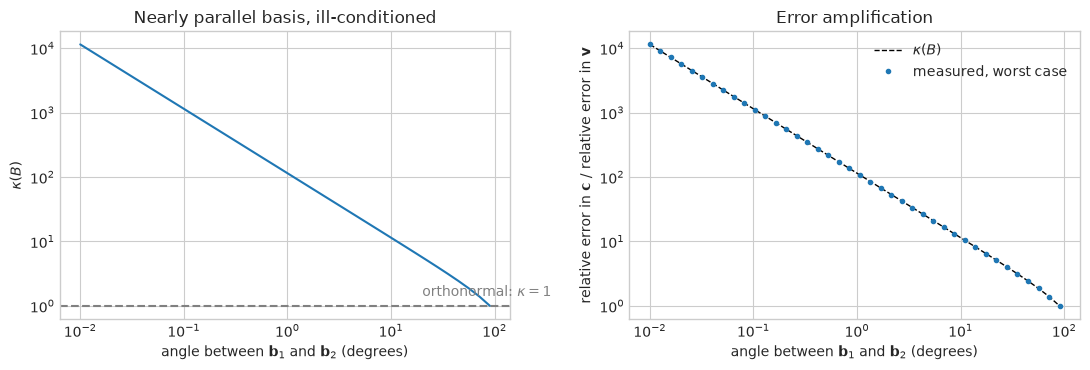

In [7]:
angles = np.radians(np.logspace(-2, np.log10(90), 40))
kappas, amplification = [], []
for th in angles:
    B_th = np.array([[1.0, np.cos(th)], [0.0, np.sin(th)]])
    kappas.append(condition_number(B_th))
    U_th = np.linalg.svd(B_th)[0]
    v0, dv = U_th[:, 0], 1e-6 * U_th[:, 1]  # worst case: v along u_1, error along u_2
    c0, c1 = np.linalg.solve(B_th, v0), np.linalg.solve(B_th, v0 + dv)
    amplification.append((np.linalg.norm(c1 - c0) / np.linalg.norm(c0)) / 1e-6)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a in ax:
    a.set_xscale("log")
    a.set_yscale("log")
    a.set_xlabel(r"angle between $\mathbf{b}_1$ and $\mathbf{b}_2$ (degrees)")
ax[0].plot(np.degrees(angles), kappas)
ax[0].axhline(1, c="gray", ls="--")
ax[0].text(20, 1.4, r"orthonormal: $\kappa = 1$", c="gray")
ax[0].set(ylabel=r"$\kappa(B)$", title="Nearly parallel basis, ill-conditioned")
ax[1].plot(np.degrees(angles), kappas, "k--", lw=1, label=r"$\kappa(B)$")
ax[1].plot(np.degrees(angles), amplification, "o", ms=3, label="measured, worst case")
ax[1].set(ylabel="relative error in $\\mathbf{c}$ / relative error in $\\mathbf{v}$", title="Error amplification")
ax[1].legend()
fig.tight_layout()
plt.show()

## 7. The DFT is a unitary change of basis

The discrete Fourier transform of a signal $\mathbf{x} \in \mathbb{C}^N$ is a matrix product, $\hat{\mathbf{x}} = F\mathbf{x}$, with the normalized **Fourier matrix**

$$
F_{kn} = \frac{1}{\sqrt N}\,e^{-j2\pi kn/N}, \qquad k, n = 0, \dots, N-1.
$$

Row $k$ is a complex sinusoid of frequency $k$, and these rows are orthonormal:

$$
\boxed{F^HF = I}, \qquad \boxed{F^{-1} = F^H}.
$$

So $F$ is unitary, and everything from §2–§6 applies:

1. **Energy is conserved (Parseval):** $\|\mathbf{x}\|^2 = \|\hat{\mathbf{x}}\|^2$, i.e. $\sum_n|x_n|^2 = \sum_k|\hat x_k|^2$.
2. **Inversion is free:** $\mathbf{x} = F^H\hat{\mathbf{x}}$, no linear system to solve.
3. **Coefficients are projections:** $\hat x_k$ is the inner product of $\mathbf{x}$ with the $k$-th sinusoid (§5.2).
4. **It is perfectly conditioned:** $\kappa(F) = 1$ (§6).

The Fourier transform does not destroy or create information and does not change energy. It describes the same vector in another orthonormal basis:

> The Fourier transform is, fundamentally, a change of basis: time coordinates in, frequency coordinates out.

`np.fft.fft(x, norm="ortho")` computes exactly $F\mathbf{x}$, just much faster than the matrix product ([06 §5](06_numerical_linear_algebra_in_practice.ipynb) measures how much).

F^H F == I: True | kappa(F) = 1.0


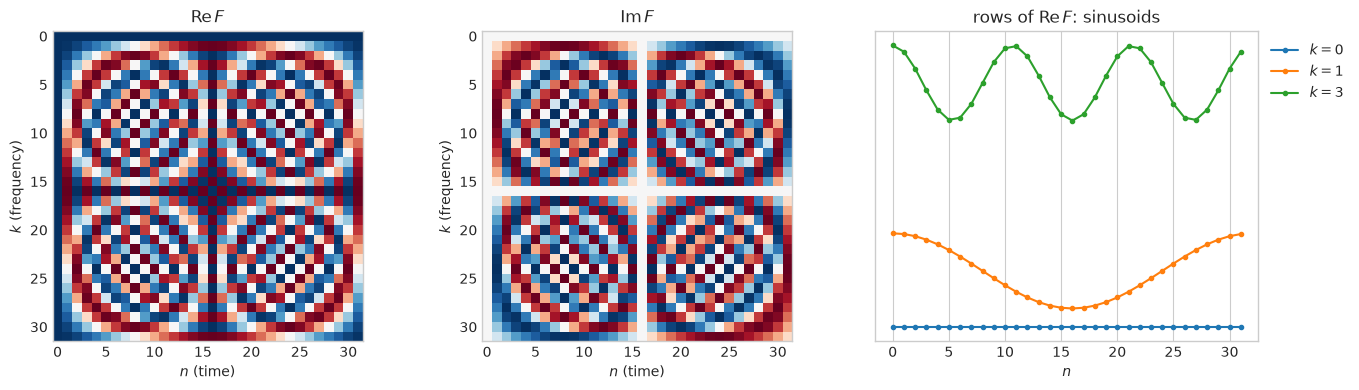

In [8]:
N = 32
F = dft_matrix(N)
print("F^H F == I:", np.allclose(F.conj().T @ F, np.eye(N)), "| kappa(F) =", round(condition_number(F), 12))

fig = plt.figure(figsize=(14, 4))
for i, (part, title) in enumerate(((F.real, r"$\mathrm{Re}\,F$"), (F.imag, r"$\mathrm{Im}\,F$"))):
    a = fig.add_subplot(1, 3, i + 1)
    a.imshow(part, cmap="RdBu", vmin=-1 / np.sqrt(N), vmax=1 / np.sqrt(N))
    a.set(xlabel="$n$ (time)", ylabel="$k$ (frequency)", title=title)
    a.grid(False)
a = fig.add_subplot(1, 3, 3)
for k in (0, 1, 3):
    a.plot(F[k].real * np.sqrt(N) + 2.5 * k, ".-", label=f"$k = {k}$")
a.set(xlabel="$n$", yticks=[], title=r"rows of $\mathrm{Re}\,F$: sinusoids")
a.legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.tight_layout()
plt.show()

A signal with two tones plus noise. Its energy is spread over all $N$ time samples, but in the frequency basis it concentrates in a few coefficients, and the total is the same. Concentration in a few coefficients is the theme of [05](05_svd_low_rank_and_dynamical_systems.ipynb); the difference is that the Fourier basis is fixed in advance, while the SVD computes its basis from the data (05 §6).

F x == np.fft.fft(x, norm='ortho'): True
energy in time: 167.358247 | energy in frequency: 167.358247
x == F^H (F x): True


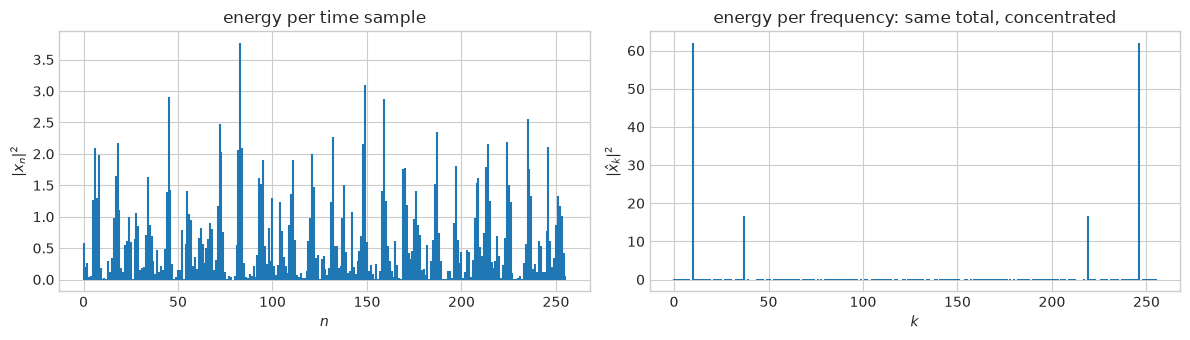

In [9]:
N = 256
n_idx = np.arange(N)
signal = np.sin(2 * np.pi * 10 * n_idx / N) + 0.5 * np.cos(2 * np.pi * 37 * n_idx / N) + 0.2 * rng.normal(size=N)
spectrum = dft_matrix(N) @ signal
print("F x == np.fft.fft(x, norm='ortho'):", np.allclose(spectrum, np.fft.fft(signal, norm="ortho")))
print(f"energy in time: {np.sum(np.abs(signal) ** 2):.6f} | energy in frequency: {np.sum(np.abs(spectrum) ** 2):.6f}")
print("x == F^H (F x):", np.allclose(dft_matrix(N).conj().T @ spectrum, signal))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].stem(n_idx, np.abs(signal) ** 2, markerfmt=" ", basefmt=" ")
ax[0].set(xlabel="$n$", ylabel="$|x_n|^2$", title="energy per time sample")
ax[1].stem(n_idx, np.abs(spectrum) ** 2, markerfmt=" ", basefmt=" ")
ax[1].set(xlabel="$k$", ylabel=r"$|\hat{x}_k|^2$", title="energy per frequency: same total, concentrated")
fig.tight_layout()
plt.show()

## 8. The SVD: unitary matrices orient, singular values deform

Every matrix, square or not, factors as

$$
\boxed{A = U\Sigma V^H}
$$

with $U$, $V$ unitary and $\Sigma$ diagonal with non-negative entries $\sigma_1 \geq \sigma_2 \geq \dots \geq 0$ ([05 §2](05_svd_low_rank_and_dynamical_systems.ipynb)). Read right to left, $A\mathbf{x}$ is three steps:

```text
x
│
▼
Vᴴ  →  rotate / reflect: change to the input basis       (no deformation)
│
▼
Σ   →  stretch or compress each axis independently by σ_k  (all the deformation)
│
▼
U   →  rotate / reflect: change to the output basis      (no deformation)
│
▼
Ax
```

So the unit circle becomes an ellipse whose semi-axes have lengths $\sigma_k$ and point along the columns $\mathbf{u}_k$ of $U$. This answers §1 in general:

> Unitary matrices do not change distances. The singular values contain the deformation.

Even the shear of §1 is "rotate, stretch along two perpendicular axes, rotate". Its singular values are $\sigma_{1,2} = (\sqrt5 \pm 1)/2$, so $\kappa = \sigma_1/\sigma_2 \approx 2.6$.

singular values: [1.61803399 0.61803399] | expected: [np.float64(1.618033988749895), np.float64(0.6180339887498949)]


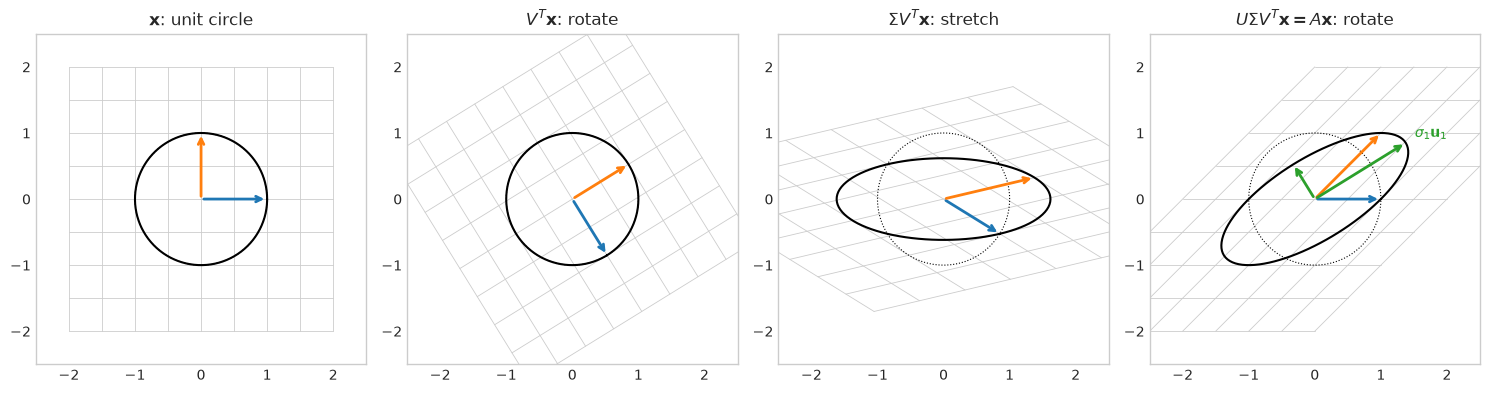

In [10]:
A_shear = np.array([[1.0, 1.0], [0.0, 1.0]])
U2, s2, VT2 = np.linalg.svd(A_shear)
print("singular values:", s2, "| expected:", [(np.sqrt(5) + 1) / 2, (np.sqrt(5) - 1) / 2])

steps = [
    (np.eye(2), r"$\mathbf{x}$: unit circle"),
    (VT2, r"$V^T\mathbf{x}$: rotate"),
    (np.diag(s2) @ VT2, r"$\Sigma V^T\mathbf{x}$: stretch"),
    (U2 @ np.diag(s2) @ VT2, r"$U\Sigma V^T\mathbf{x} = A\mathbf{x}$: rotate"),
]
fig, ax = plt.subplots(1, 4, figsize=(15, 4))
for a, (M, title) in zip(ax, steps, strict=True):
    plot_linear_map(a, M, title)
for k in range(2):
    ax[3].annotate("", s2[k] * U2[:, k], (0, 0), arrowprops={"arrowstyle": "->", "color": "C2", "lw": 2})
ax[3].text(*(s2[0] * U2[:, 0] * 1.1), r"$\sigma_1\mathbf{u}_1$", c="C2")
fig.tight_layout()
plt.show()

### 8.1 A worked example

The symmetric matrix below has singular values $7, 5, 3, 1$. Keeping the two largest gives the best rank-2 approximation ([05 §4](05_svd_low_rank_and_dynamical_systems.ipynb)), and the error is set by the singular values thrown away: $\|A - A_2\|_F = \sqrt{3^2 + 1^2} = \sqrt{10} \approx 3.162$ and $\|A - A_2\|_2 = \sigma_3 = 3$.

$$
A = \begin{bmatrix}4&1&2&0\\1&4&0&2\\2&0&4&1\\0&2&1&4\end{bmatrix},
\qquad
A_2 = \begin{bmatrix}3&0.5&3&0.5\\0.5&3&0.5&3\\3&0.5&3&0.5\\0.5&3&0.5&3\end{bmatrix}.
$$

In [11]:
A4 = np.array([[4, 1, 2, 0], [1, 4, 0, 2], [2, 0, 4, 1], [0, 2, 1, 4]], dtype=float)
A4_2 = low_rank_approx(A4, 2)
print("singular values:", np.linalg.svd(A4, compute_uv=False))
print("A_2 =\n", A4_2.round(3))
print(f"||A - A_2||_F = {np.linalg.norm(A4 - A4_2):.3f} | ||A - A_2||_2 = {np.linalg.norm(A4 - A4_2, 2):.3f}")

singular values: [7. 5. 3. 1.]
A_2 =
 [[3.  0.5 3.  0.5]
 [0.5 3.  0.5 3. ]
 [3.  0.5 3.  0.5]
 [0.5 3.  0.5 3. ]]
||A - A_2||_F = 3.162 | ||A - A_2||_2 = 3.000


## 9. A mental map

```text
INNER PRODUCT
      │
      ▼
    NORM
      │
      ▼
ORTHOGONALITY
      │
      ▼
ORTHOGONAL / UNITARY MATRICES  (U^H U = I)
      │
      ├──────────► preserve energy ─────────► Parseval            §3, §7
      │
      ├──────────► change of basis ─────────► Fourier (fixed basis) §5, §7
      │                 │
      │                 └─ any invertible B works; unitary gives c_i = u_i^H v and κ = 1   §5, §6
      │
      └──────────► SVD:  A = U Σ Vᴴ                                §8 → 05
                         U, V: orientation (no deformation)
                         Σ:    all the deformation
```

Next, [05](05_svd_low_rank_and_dynamical_systems.ipynb) uses the SVD to find low-rank structure in data, and [06](06_numerical_linear_algebra_in_practice.ipynb) looks at how the SVD and the FFT are actually computed.